# FermiHubbard1D — Periodic Boundary Conditions

Demonstrates the `periodic=True` flag added in Task 18.
Check by hand:
- OBC vs PBC spectra visibly differ for L ≥ 3
- Both orderings agree on the PBC spectrum
- Free-fermion limit E₀ = −4t at L=4 (PBC tight-binding)
- JW string weights for the boundary bonds

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qaravan.core.hamiltonians import FermiHubbard1D
from qaravan.plot import set_style

set_style()

## 1. Boundary term structure

Inspect the terms added by `periodic=True` and verify their site lists and Pauli strings.

In [2]:
L = 3
for ordering in ["stacked", "interleaved"]:
    fh_obc = FermiHubbard1D(L, t=1.0, U=1.0, ordering=ordering, periodic=False)
    fh_pbc = FermiHubbard1D(L, t=1.0, U=1.0, ordering=ordering, periodic=True)
    extra = fh_pbc.terms[len(fh_obc.terms):]  # the boundary bonds
    print(f"\n{ordering} — boundary terms added by PBC:")
    for term in extra:
        for ps in term.local_obs.terms:
            print(f"  sites={term.sites}  Pauli='{ps.string}'  coeff={ps.coeff:.3f}")


stacked — boundary terms added by PBC:
  sites=[0, 1, 2]  Pauli='XZX'  coeff=-0.500+0.000j
  sites=[0, 1, 2]  Pauli='YZY'  coeff=-0.500+0.000j
  sites=[3, 4, 5]  Pauli='XZX'  coeff=-0.500+0.000j
  sites=[3, 4, 5]  Pauli='YZY'  coeff=-0.500+0.000j

interleaved — boundary terms added by PBC:
  sites=[0, 1, 2, 3, 4]  Pauli='XZZZX'  coeff=-0.500+0.000j
  sites=[0, 1, 2, 3, 4]  Pauli='YZZZY'  coeff=-0.500+0.000j
  sites=[1, 2, 3, 4, 5]  Pauli='XZZZX'  coeff=-0.500+0.000j
  sites=[1, 2, 3, 4, 5]  Pauli='YZZZY'  coeff=-0.500+0.000j


**Expected (stacked, L=3):**  
↑ boundary: sites `[0,1,2]`, Paulis `XZX` and `YZY` with coeff −0.5  
↓ boundary: sites `[3,4,5]`, same Paulis  

**Expected (interleaved, L=3):**  
↑ boundary: sites `[0,1,2,3,4]`, Paulis `XZZZX` and `YZZZY` with coeff −0.5  
↓ boundary: sites `[1,2,3,4,5]`, same Paulis

## 2. OBC vs PBC spectrum

PBC lowers the ground-state energy (ring has more hopping channels).
Stacked and interleaved must agree on each.

In [3]:
print(f"{'L':>3}  {'ordering':>12}  {'E0 OBC':>10}  {'E0 PBC':>10}  {'ΔE':>8}")
print("-" * 52)
for L in [2, 3, 4]:
    for ordering in ["stacked", "interleaved"]:
        fh_o = FermiHubbard1D(L, t=1.0, U=2.0, ordering=ordering, periodic=False)
        fh_p = FermiHubbard1D(L, t=1.0, U=2.0, ordering=ordering, periodic=True)
        E_o = np.linalg.eigvalsh(fh_o.as_matrix())[0]
        E_p = np.linalg.eigvalsh(fh_p.as_matrix())[0]
        print(f"{L:>3}  {ordering:>12}  {E_o:>10.5f}  {E_p:>10.5f}  {E_p-E_o:>8.5f}")

  L      ordering      E0 OBC      E0 PBC        ΔE
----------------------------------------------------
  2       stacked    -1.23607    -3.12311  -1.88704
  2   interleaved    -1.23607    -3.12311  -1.88704
  3       stacked    -2.27945    -3.46410  -1.18465
  3   interleaved    -2.27945    -3.46410  -1.18465
  4       stacked    -3.06954    -3.62721  -0.55768
  4   interleaved    -3.06954    -3.62721  -0.55768


**Check:** stacked and interleaved rows for the same L should agree on E0 OBC and E0 PBC to machine precision.

## 3. Free-fermion PBC: analytical check

At U=0, PBC: $\varepsilon_k = -2t\cos(2\pi k/L)$.  
For L=4, half-filling (2 electrons per spin): fill $\varepsilon_0 = -2t$ and $\varepsilon_1 = 0$.  
Total ground energy = $2 \times (-2t + 0) = -4t$.

In [4]:
L, t = 4, 1.0
pbc_levels = sorted(-2 * t * np.cos(2 * np.pi * k / L) for k in range(L))
expected = 2 * sum(pbc_levels[: L // 2])
print(f"PBC tight-binding levels: {[f'{e:.3f}' for e in pbc_levels]}")
print(f"Expected E0 (both spins, half-filling): {expected:.5f}")

for ordering in ["stacked", "interleaved"]:
    fh = FermiHubbard1D(L, t=t, U=0.0, ordering=ordering, periodic=True)
    E0 = np.linalg.eigvalsh(fh.as_matrix())[0]
    print(f"  {ordering}: E0 = {E0:.8f}  (error {abs(E0 - expected):.2e})")

PBC tight-binding levels: ['-2.000', '-0.000', '0.000', '2.000']
Expected E0 (both spins, half-filling): -4.00000
  stacked: E0 = -4.00000000  (error 2.66e-15)
  interleaved: E0 = -4.00000000  (error 6.22e-15)


## 4. Full spectrum: OBC vs PBC

Plot the full spectrum for L=3 to see how PBC shifts all levels, not just the ground state.

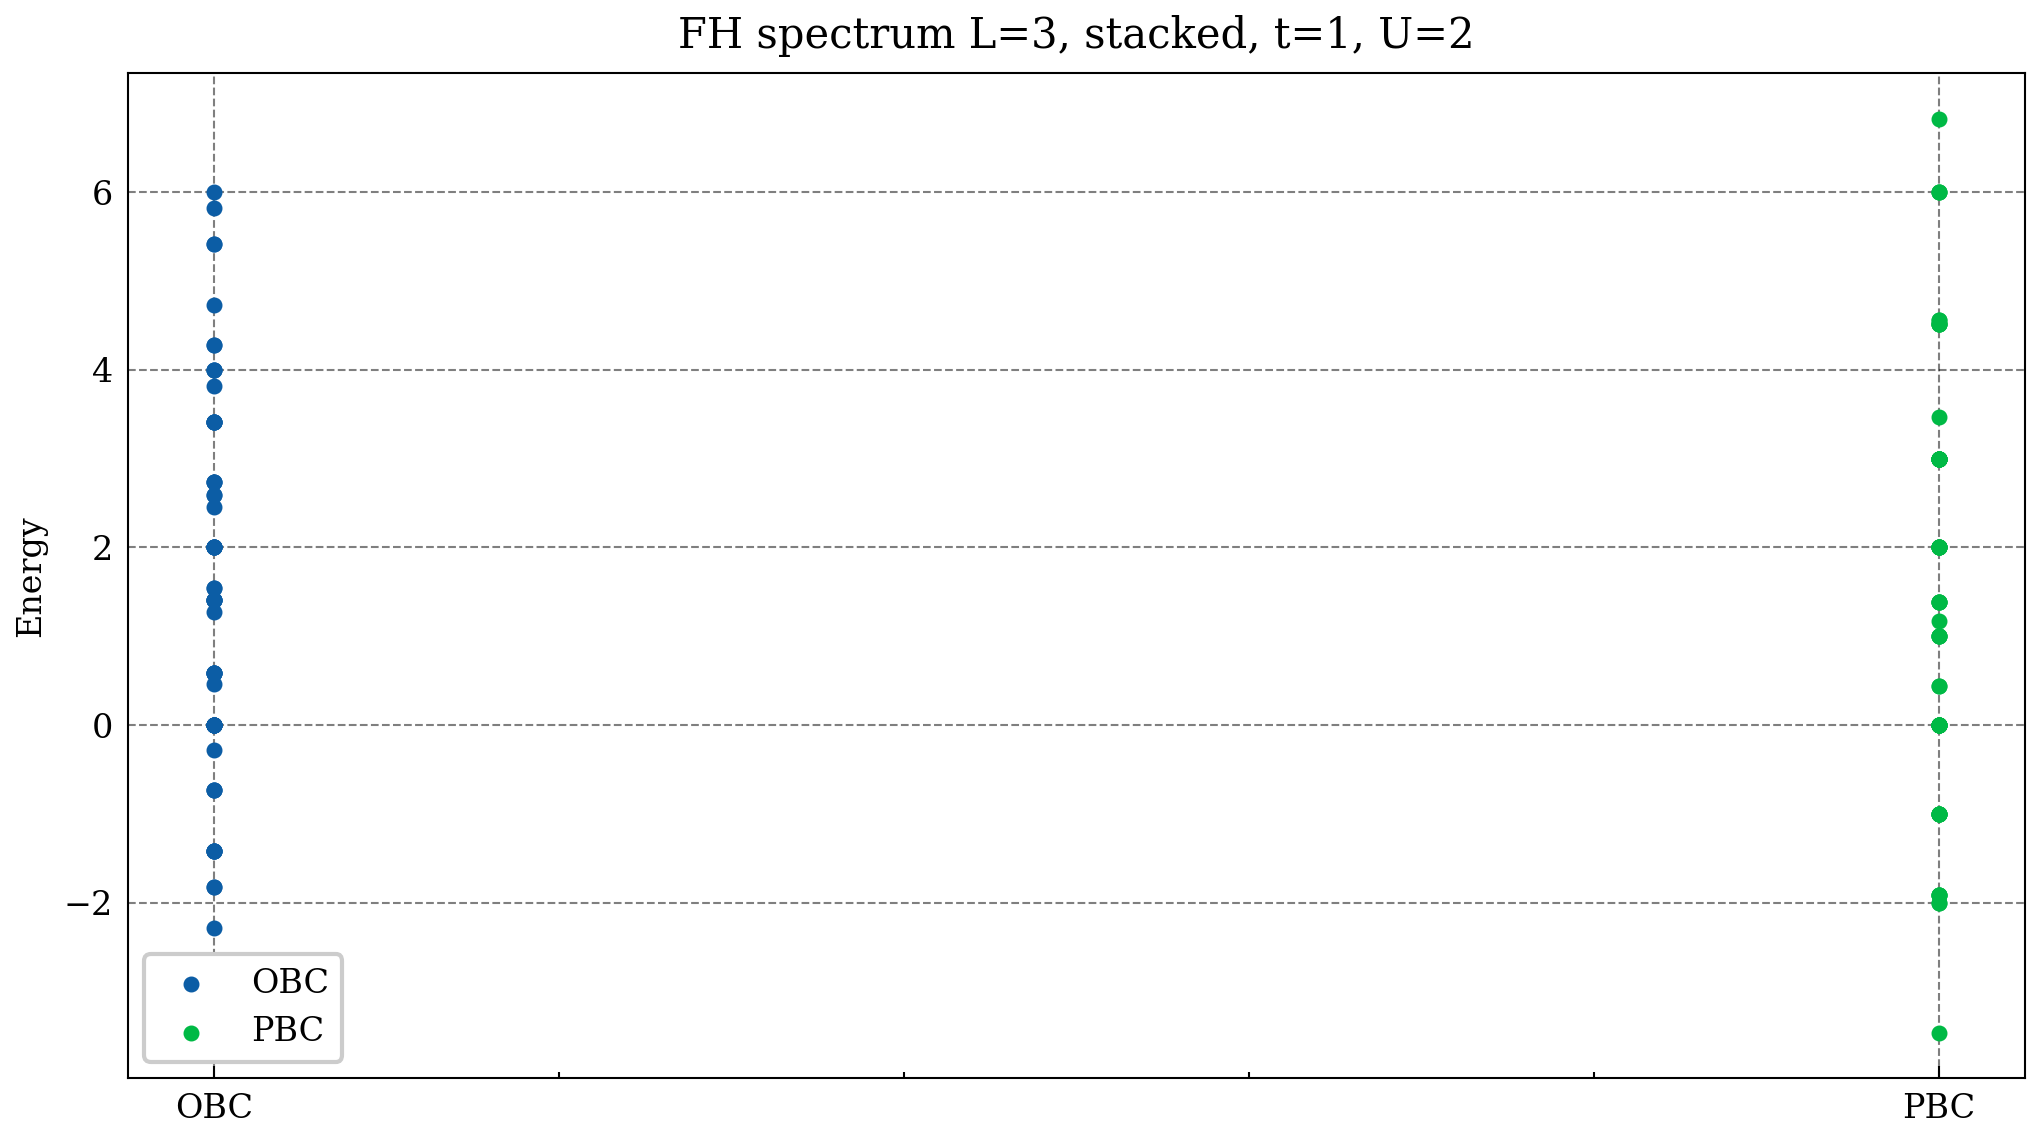

In [5]:
L = 3
fh_obc = FermiHubbard1D(L, t=1.0, U=2.0, ordering="stacked", periodic=False)
fh_pbc = FermiHubbard1D(L, t=1.0, U=2.0, ordering="stacked", periodic=True)
E_obc = np.linalg.eigvalsh(fh_obc.as_matrix())
E_pbc = np.linalg.eigvalsh(fh_pbc.as_matrix())

fig, ax = plt.subplots(figsize=(7, 4))
x_obc = np.zeros(len(E_obc))
x_pbc = np.ones(len(E_pbc))
ax.scatter(x_obc, E_obc, s=8, label="OBC")
ax.scatter(x_pbc, E_pbc, s=8, label="PBC")
ax.set_xticks([0, 1])
ax.set_xticklabels(["OBC", "PBC"])
ax.set_ylabel("Energy")
ax.set_title(f"FH spectrum L={L}, stacked, t=1, U=2")
ax.legend()
plt.tight_layout()
plt.show()

## 5. L=1 guard

`periodic=True` with a single fermion site has no meaningful ring topology and must raise.

In [6]:
try:
    FermiHubbard1D(1, periodic=True)
    print("ERROR: should have raised ValueError")
except ValueError as exc:
    print(f"Correctly raised ValueError: {exc}")

Correctly raised ValueError: periodic=True requires num_fermions >= 2.
